&nbsp;

# `ChIP-Atlas` Enrichment Analysis Result parse notebook (promoter-level activity: PLA)

- 2026-05-29: background data を、GENCODE version 49 transcript が近傍にある CRE のみに限定
- 2026-07-07: クエリのデータを bulk RNA-seq data の メタ解析 で得た 全てのタイプの遺伝子 (protein-coding, lncRNA) の近傍に位置する シスエレメントを対象とする

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import plotly.express as px
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from upsetplot import UpSet, from_contents
from adjustText import adjust_text


pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(100)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
Execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {Execute_date}")

Execute Date: 260912


&nbsp;

&nbsp;

&nbsp;

## Rules for Visualization

- [ChIP-Atlas: Enrichment Analysis](https://chip-atlas.org/enrichment_analysis) で得られた結果のうち、以下に示す特徴を持つデータは取り除く

1. `Fold enrichment == 0`
2. `-log10_pvalue == -0.0`

&nbsp;

&nbsp;

&nbsp;

## 1. Heat stress-related ATAC-seq metadata

- related notebook: [../metadata/12_8_metadata_atacseq.ipynb](../metadata/12_8_metadata_atacseq.ipynb)

In [3]:
hs_atacseq_metadata = pl.read_csv(
    "../../Data/metadata/metadata_2608/atacseq_metadata_all_260802.tsv",
    separator='\t'
).rename(
    {
        "sample_heat_id": "experiment_id"
    }
)

pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(80)
display(hs_atacseq_metadata)

experiment_id,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_molecule_ch1,sample_description,sample_platform_id,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_series_id,cell_line,genome_build,sample_accession,reference_doi,stress treatment temperature,stress treatment time,control treatment temperature,is_chip_atlas_registered,library_selection,secondary_study_accession,study_title,description,cell_type,library_strategy,library_source,library_layout,library_construction_protocol,experiment_alias,center_name,scientific_name,tax_id,study_accession,secondary_sample_accession,treatment,stress_with,replicate,sample_characteristics_ch1,preconditioning,genotype
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,bool,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str
"""SRX3316069""","""SRX3316067""","""hs_fast_atac-seq_rep1 vs fast_…","""other""","""Homo sapiens""","""PAIRED""","""SRA""","""SRR6206775 vs SRR6206773""","""HS Fast ATAC-Seq Rep1 vs Fast …","""GSM2829008 vs GSM2829006""","""Public on Aug 03 2018""","""Oct 24 2017""","""May 15 2019""","""SRA""","""H9 hESCs""","""Homo sapiens""",9606,"""genomic DNA""","""fast ATAC-Seq, Fast ATAC-Seq u…","""GPL11154""","""Illumina HiSeq 2000""","""other""","""genomic""","""ATAC-seq""","""GSM2829008 vs GSM2829006""","""GSE105028""","""hESC""","""hg38""","""SAMN07828432 vs SAMN07828392""","""https://doi.org/10.1016/j.molc…","""42 C""","""60 min.""","""unknown (maybe 37 C)""",false,"""other""","""SRP120027""","""Architectural proteins and plu…","""Illumina HiSeq 2000 sequencing…","""H9 human Embryonic Stem Cell L…","""ATAC-seq""","""GENOMIC""","""PAIRED""","""For Hi-C, cells were crosslink…","""GSM2829008 vs GSM2829006""","""GEO""","""Homo sapiens""",9606,"""PRJNA414442""","""SRS2621656 vs SRS2621654""",null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""SRX10705951""","""SRX10705949""","""atacseq_lymphblastoid_cells_t2…","""other""","""Homo sapiens""","""PAIRED""","""SRA""","""SRR14352104 vs SRR14352102""","""ATACseq_Lymphblastoid cells_T2…","""GSM5269436 vs GSM5269434""","""Public on Apr 21 2023""","""Apr 28 2021""","""Apr 21 2023""","""SRA""","""lymphoblastoid-EBV immortalize…","""Homo sapiens""",9606,"""genomic DNA""","""Ethan_T21, genomic DNA (ATAC-s…","""GPL18573""","""Illumina NextSeq 500""","""other""","""genomic""","""ATAC-seq""","""GSM5269436 vs GSM5269434""","""GSE173536""",null,"""hg38 (GRCh38)""","""SAMN18915517 vs SAMN18915519""","""https://doi.org/10.1371/journa…","""42 C""","""60 min.""","""unknown (maybe 37 C)""",true,"""other""","""SRP316796""","""Blood cells with trisomy 21 ov…","""NextSeq 500 sequencing: GSM526…","""lymphoblastoid""","""ATAC-seq""","""GENOMIC""","""PAIRED""","""Suspension cells were then use…","""GSM5269436 vs GSM5269434""","""GEO""","""Homo sapiens""",9606,"""PRJNA725915""","""SRS8795768 vs SRS8795765""","""42C 1 hour heat shock vs untre…",null,null,null,null,"""chromosome 21 trisomic"""


In [4]:
up5p_all_pla_fantabio_chipseq_atacseq_enrichment = pl.read_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/up5p_all_cre_pla_atac.tsv",
    separator="\t",
    has_header=False,
    infer_schema_length=10000,
    new_columns=[
        "experiment_id",
        "experiment_type",
        "feature",
        "cell_class",
        "cell",
        "num_of_peaks",
        "overlaps_with_cre",
        "overlaps_with_permutation_genome_region",
        "log10_pvalue",
        "log10_qvalue",
        "fold_enrichment"
    ]
).filter(
    pl.col("fold_enrichment") != 0
).with_columns(
    pl.col("fold_enrichment").log(base=2).alias("log2_fold_enrichment"),
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue"),
    # Parse ratio columns
    (
        pl.col("overlaps_with_cre").str.split("/").list.get(0).cast(pl.Int64) /
        pl.col("overlaps_with_cre").str.split("/").list.get(1).cast(pl.Int64)
    ).alias("overlaps_with_cre_ratio"),
).with_columns(
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue")
).drop(
    "fold_enrichment",
    "log10_pvalue",
    "log10_qvalue"
).filter(
    ((pl.col("-log10_pvalue") != -0.0) & # p-value が 算出できていない場合は除外
    (pl.col("-log10_qvalue") != -0.0)) # q-value が 算出できていない場合は除外
)

pl.Config.set_tbl_rows(10)
display(up5p_all_pla_fantabio_chipseq_atacseq_enrichment)

experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio
str,str,str,str,str,i64,str,str,f64,f64,f64,f64
"""SRX19272592""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Erythroid Cells""",5120,"""4075/14577""","""6826/51838""",1.086077,324.0,324.0,0.27955
"""SRX19272593""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Erythroid Cells""",6091,"""4822/14577""","""8166/51838""",1.070321,324.0,324.0,0.330795
"""SRX22045420""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Monocytes-CD14+""",6173,"""4423/14577""","""7547/51838""",1.059438,324.0,324.0,0.303423
"""SRX19272595""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Erythroid Cells""",6206,"""4881/14577""","""8340/51838""",1.057443,324.0,324.0,0.334843
"""SRX4991891""","""ATAC-Seq""","""ATAC-Seq""","""Uterus""","""HeLa""",5072,"""3940/14577""","""6746/51838""",1.05448,324.0,324.0,0.270289
…,…,…,…,…,…,…,…,…,…,…,…
"""SRX10194304""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""GM12878""",106,"""13/14577""","""43/51838""",0.104498,0.0597093,0.0538025,0.000892
"""SRX10950323""","""ATAC-Seq""","""ATAC-Seq""","""Pluripotent stem cell""","""hESC H9""",252,"""13/14577""","""44/51838""",0.071323,0.0589834,0.0530902,0.000892
"""SRX8588620""","""ATAC-Seq""","""ATAC-Seq""","""Cardiovascular""","""Pulmonary artery endothelial c…",702,"""12/14577""","""48/51838""",-0.169683,0.0575216,0.0516422,0.000823


In [5]:
up5p_all_pla_atacseq_filtered = up5p_all_pla_fantabio_chipseq_atacseq_enrichment.join(
    hs_atacseq_metadata,
    on="experiment_id",
    how="inner"
).filter(
    pl.col("-log10_pvalue") != -0.0 # p-value が 算出できていない場合は除外
).unique().sort(
    by=["-log10_qvalue", "log2_fold_enrichment"],
    descending=[True, True]
).with_columns(
        pl.concat_str(
            [
                pl.col("sample_series_id"),
                pl.col("cell"),
                pl.col("stress treatment temperature"),
                pl.col("stress treatment time"),
            ],
            separator=", ",  # delimiter between fields
            ignore_nulls=True,  # skip null values instead of propagating null
        ).alias("experiment_details")
)

# 念のため保存する
up5p_all_pla_atacseq_filtered.write_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/filtered/up5p_all_cre_pla_atac_filtered.tsv",
    separator="\t",
    include_header=True
)

print(f"HS-relatedATAC-seq experiments: {up5p_all_pla_atacseq_filtered.select('experiment_id').n_unique()}")
display(up5p_all_pla_atacseq_filtered)

HS-relatedATAC-seq experiments: 27


experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_molecule_ch1,sample_description,sample_platform_id,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_series_id,cell_line,genome_build,sample_accession,reference_doi,stress treatment temperature,stress treatment time,control treatment temperature,is_chip_atlas_registered,library_selection,secondary_study_accession,study_title,description,cell_type,library_strategy,library_source,library_layout,library_construction_protocol,experiment_alias,center_name,scientific_name,tax_id,study_accession,secondary_sample_accession,treatment,stress_with,replicate,sample_characteristics_ch1,preconditioning,genotype,experiment_details
str,str,str,str,str,i64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,bool,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str
"""SRX24613860""","""ATAC-Seq""","""ATAC-Seq""","""Cardiovascular""","""HUVEC""",26467,"""7553/14577""","""14994/51838""",0.841055,324.0,324.0,0.518145,"""SRX24613858""","""huvec_atac-seq_39_°c_heat_stre…","""null""","""null""","""null""","""null""","""SRR29089716 vs SRR29089718""","""HUVEC, ATAC-Seq, 39 °C heat st…","""GSM8281745 vs GSM8281743""","""Public on May 25 2024""","""May 20 2024""","""May 25 2024""","""SRA""","""HUVEC""","""Homo sapiens""",9606,"""genomic DNA""","""HUVEC, ATAC-Seq, 39 °C heat st…","""GPL24676""","""Illumina NovaSeq 6000""","""other""","""genomic""","""ATAC-seq""","""GSM8281745 vs GSM8281743""","""GSE267931""","""HUVEC""","""T2T-CHM13v2.0 from Ensembl rap…","""SAMN41463534 vs SAMN41463536""","""https://doi.org/10.1101/2023.1…","""39 C""","""120 min.""","""unknown (maybe 37 C)""",true,"""other""","""SRP508795""","""Inflammatory stress-mediated c…","""Illumina NovaSeq 6000 sequenci…","""vascular endothelial""","""ATAC-seq""","""GENOMIC""","""PAIRED""","""HUVEC cells were grown in dish…","""GSM8281745_r1 vs GSM8281743_r1""",null,"""Homo sapiens""",9606,"""PRJNA1113657""","""SRS21351095 vs SRS21351093""","""heat stress vs control""",null,null,null,null,null,"""GSE267931, HUVEC, 39 C, 120 mi…"
"""SRX10705939""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Lymphoblastoid cell line""",20310,"""6670/14577""","""13443/51838""",0.819219,324.0,324.0,0.45757,"""SRX10705938""","""atacseq_lymphblastoid_cells_d2…","""other""","""Homo sapiens""","""PAIRED""","""SRA""","""SRR14352092 vs SRR14352091""","""ATACseq_Lymphblastoid cells_D2…","""GSM5269424 vs GSM5269423""","""Public on Apr 21 2023""","""Apr 28 2021""","""Apr 21 2023""","""SRA""","""lymphoblastoid-EBV immortalize…","""Homo sapiens""",9606,"""genomic DNA""","""Eric_D21, genomic DNA (ATAC-se…","""GPL18573""","""Illumina NextSeq 500""","""other""","""genomic""","""ATAC-seq""","""GSM5269424 vs GSM5269423""","""GSE173536""",null,"""hg38 (GRCh38)""","""SAMN18915529 vs SAMN18915530""","""https://doi.org/10.1371/journa…","""42 C""","""60 min.""","""unknown (maybe 37 C)""",true,"""other""","""SRP316796""","""Blood cells with trisomy 21 ov…","""NextSeq 500 sequencing: GSM526…","""lymphoblastoid""","""ATAC-seq""","""GENOMIC""","""PAIRED""","""Suspension cells were then use…","""GSM5269424 vs GSM5269423""","""GEO""","""Homo sapiens""",9606,"""PRJNA725915""","""SRS8795756 vs SRS8795755""","""42C 1 hour heat shock vs untre…",null,null,null,null,"""disomic""","""GSE173536, Lymphoblastoid cell…"
"""SRX10705941""","""ATAC-Seq""","""ATAC-Seq""","""Blood""","""Lymphoblastoid cell line""",23458,"

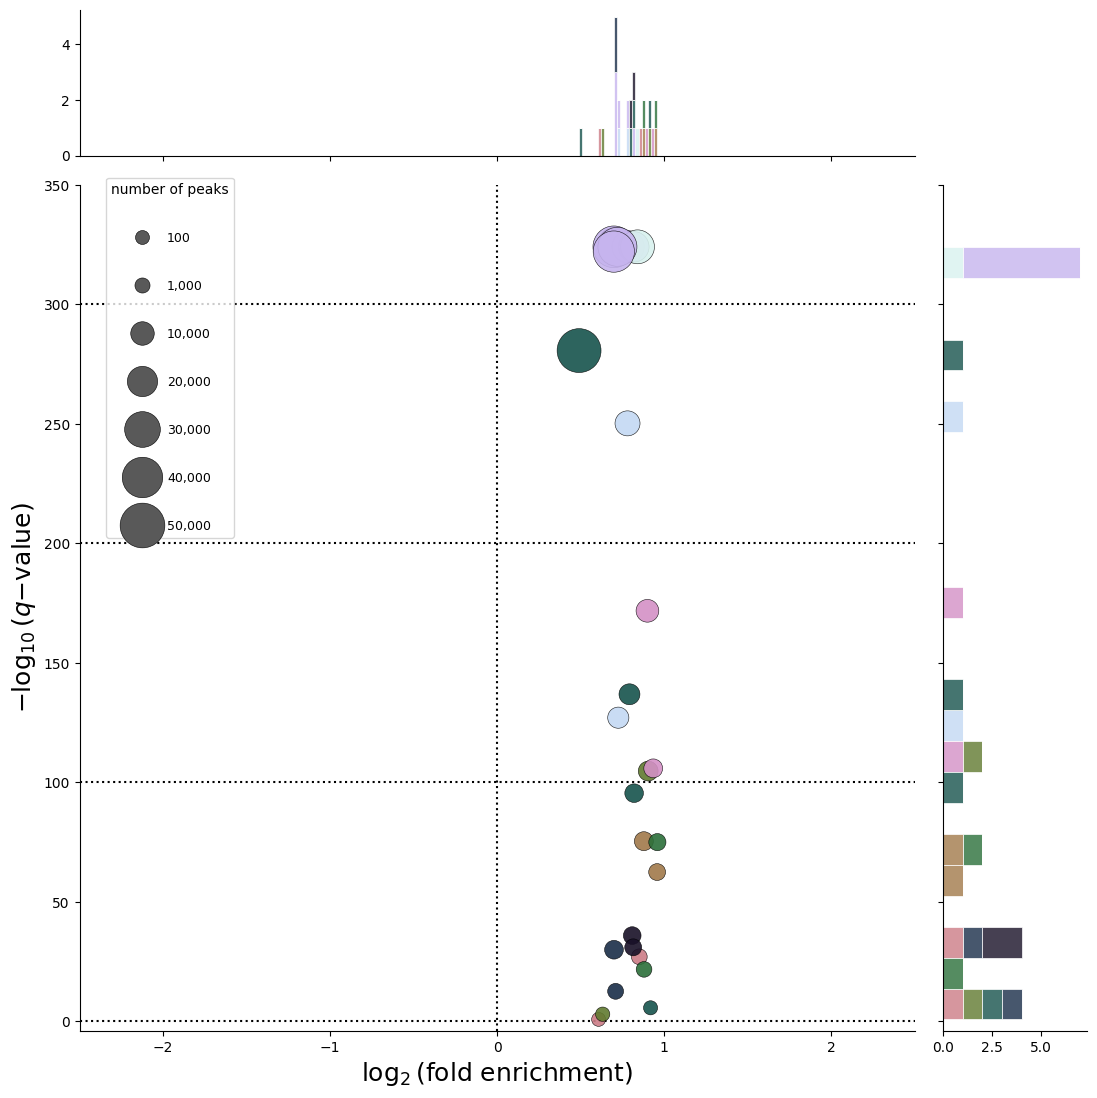

In [6]:
# =============================================================================
# ATAC-seq enrichment volcano-style JointGrid (main figure)
# - Center: scatter (x = log2 fold enrichment, y = -log10 q-value)
# - Top / right: marginal histograms
# - Size legend (number of peaks) is drawn on this figure (same axes as scatter)
# - Experiment-details color legend is drawn in the NEXT cell (for slide layout)
# =============================================================================

# --- 1. Load plotting table (pandas for Seaborn) ---
# Source: inner join of ChIP-Atlas enrichment results and heat-stress ATAC metadata
atac_viz = (
    up5p_all_pla_atacseq_filtered
    .unique(subset=["experiment_id"], keep="first")
    .to_pandas()
)

# --- 2. Color mapping for experiment_details (hue) ---
# Fix category order so colors stay consistent between this plot and the legend cell
experiment_labels = sorted(atac_viz["experiment_details"].unique())
palette = sns.color_palette("cubehelix", n_colors=len(experiment_labels))
experiment_colors = dict(zip(experiment_labels, palette))  # used in the next cell for the legend

# --- 3. Size mapping for num_of_peaks (bubble area) ---
# min/max marker area in points^2; Seaborn scales num_of_peaks linearly between these
SCATTER_SIZES = (100, 1000)

peaks_min = atac_viz["num_of_peaks"].min()
peaks_max = atac_viz["num_of_peaks"].max()

# Fixed legend steps (log-spaced enough to show visible size differences)
SIZE_LEGEND_VALUES = [100, 1000, 10000, 20000, 30000, 40000, 50000]

def _peak_to_markersize(peak_val):
    # Same linear area mapping as seaborn scatterplot (sizes=SCATTER_SIZES)
    s_min, s_max = SCATTER_SIZES
    area = s_min + (peak_val - peaks_min) / (peaks_max - peaks_min) * (s_max - s_min)
    return np.sqrt(area)

# --- 4. Create JointGrid layout ---
# hue is set here; size is set in plot_joint below
g = sns.JointGrid(
    data=atac_viz,
    x="log2_fold_enrichment",
    y="-log10_qvalue",
    hue="experiment_details",
    palette=palette,
    hue_order=experiment_labels,
    height=11,
    ratio=5,              # center panel height vs marginal width
    marginal_ticks=True,
)

# --- 5. Center panel: bubble scatter ---
g.plot_joint(
    sns.scatterplot,
    data=atac_viz,
    size="num_of_peaks",
    sizes=SCATTER_SIZES,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --- 6. Build size-legend handles (same scaling as the scatter points above) ---
size_legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=_peak_to_markersize(v),
        markerfacecolor="0.35",
        markeredgecolor="black",
        markeredgewidth=0.4,
    )
    for v in SIZE_LEGEND_VALUES
]
size_legend_labels = [f"{v:,}" for v in SIZE_LEGEND_VALUES]

# --- 7. Marginal panels: stacked histograms by experiment_details ---
g.plot_marginals(
    sns.histplot,
    bins=25,
    multiple="stack",     # stack bars colored by experiment_details (same hue as center)
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
)

# --- 8. Remove any leftover legends (e.g. from histplot) ---
for ax in (g.ax_joint, g.ax_marg_x, g.ax_marg_y):
    if ax.legend_ is not None:
        ax.legend_.remove()

# --- 9. Axis limits and labels ---
g.ax_joint.set_xlim(-2.5, 2.5)
g.ax_joint.set_ylim(-4, 350)
g.ax_joint.set_xlabel(r"$\log_{2}$(fold enrichment)", fontsize=18)
g.ax_joint.set_ylabel(r"$-\log_{10}(q\mathrm{-value})$", fontsize=18)

# --- 10. Reference lines (volcano-style guides) ---
# x = 0  -> fold enrichment = 1 (no change on log2 scale)
g.ax_joint.axvline(x=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=0,   color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=100,  color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=200,  color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=300,  color="black", linestyle=":", zorder=0)

# --- 11. Size legend on the scatter axes (same point scaling as plotted bubbles) ---
# loc="upper left" anchors the legend's top-left corner at bbox_to_anchor.
# Use a high y value (near 1.0) for top-left placement; y=0.38 would push it downward.
leg_size = g.ax_joint.legend(
    handles=size_legend_handles,
    labels=size_legend_labels,
    title="number of peaks",
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    bbox_transform=g.ax_joint.transAxes,
    ncol=1,
    frameon=True,
    framealpha=0.8,
    labelspacing=2.8,
    handletextpad=1.0,
    borderaxespad=0.8,
    title_fontsize=10,
    fontsize=9,
)

plt.show()

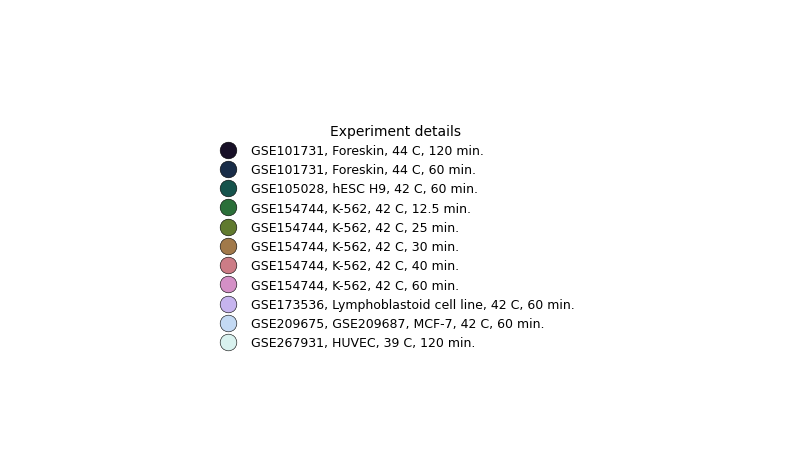

In [7]:
# --- Legend: experiment_details (color) — manual, for slide layout ---
# Size legend (number of peaks) is already on the main JointGrid figure
fig_leg_cell, ax_leg_cell = plt.subplots(figsize=(8, 0.35 * len(experiment_labels) + 1))
ax_leg_cell.axis("off")

hue_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=12,
        markerfacecolor=experiment_colors[label],
        markeredgecolor="black",
        markeredgewidth=0.4,
        label=label,
    )
    for label in experiment_labels
]

ax_leg_cell.legend(
    handles=hue_handles,
    title="Experiment details",
    loc="center",
    frameon=False,
    fontsize=9,
    title_fontsize=10,
)
fig_leg_cell.tight_layout()
# fig_leg_cell.savefig("legend_experiment.pdf", bbox_inches="tight", transparent=True)

plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

---

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 2. HS-related ChIP-seq (Histone modification)

- related notebook: [../metadata/12_8_metadata_chipseq.ipynb](../metadata/12_8_metadata_chipseq.ipynb)

In [9]:
hs_chipseq_histone_metadata = pl.read_csv(
    "../../Data/metadata/metadata_2608/chipseq_histone_modification_metadata_all_260824.tsv",
    separator='\t',
    infer_schema_length=10000
).rename(
    {
        "sample_heat_id": "experiment_id"
    }
)

pl.Config.set_tbl_rows(2)
display(hs_chipseq_histone_metadata)

experiment_id,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_molecule_ch1,sample_platform_id,sample_contact_name,sample_contact_email,sample_contact_phone,sample_contact_laboratory,sample_contact_department,sample_contact_institute,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,sample_contact_country,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_supplementary_file_1,sample_series_id,sample_data_row_count,big_key,cell_line,…,base_count,library_strategy,library_source,library_layout,status,fastq_aspera,tax_lineage,sample_alias,run_alias,library_construction_protocol,experiment_alias,cell_line_right,tag,first_created,scientific_name,tax_id,study_accession,accession,secondary_sample_accession,first_public,study_alias,sample_contact_state,condition,sample_description_right,cell_type,library_strategy_right,center_name,sample_data_processing,chip_antibody,assembly,country,cell_type_right,collection_date,library_name,basecalling,adapter_trimming,align,deduplication,peak_calling,supplementary_files_format_and_content
str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX2313416""","""SRX2313415""","""h4ac_k562_hs30 vs h4ac_k562_nh…","""ChIP""","""Homo sapiens""","""PAIRED""","""SRA""","""SRR4779641 vs SRR4779640""","""H4ac K562 HS30 vs H4ac K562 NH…","""GSM2367734 vs GSM2367733""","""Public on May 21 2017""","""Nov 01 2016""","""May 15 2019""","""SRA""",1,"""K562 cells""","""Homo sapiens""",9606,"""genomic DNA""","""GPL16791""","""Anniina,,Vihervaara""","""mavih@kth.se""","""+358 50 5463694""","""Vihervaara""","""Gene Technology""","""KTH Royal Institute of Technol…","""Tomtebodavägen 23A""","""Stockholm""","""17165""","""Sweden""","""Illumina HiSeq 2500""","""ChIP""","""genomic""","""ChIP-Seq""","""GSM2367734 vs GSM2367733""","""ftp://ftp.ncbi.nlm.nih.gov/geo…","""GSE89382""",0,"""SRX2313416 vs SRX2313415""","""K562""",…,"""5517745948 vs 6106686038""","""ChIP-Seq""","""GENOMIC""","""PAIRED""","""public""","""fasp.sra.ebi.ac.uk:/vol1/fastq…","""1;131567;2759;33154;33208;6072…","""GSM2367734 vs GSM2367733""","""GSM2367734_r1 vs GSM2367733_r1""","""After tretments, the cells wer…","""GSM2367734 vs GSM2367733""","""K562""","""env_tax:terrestrial;env_tax""","""2017-05-23""","""Homo sapiens""",9606,"""PRJNA352038""","""SRR4779641 vs SRR4779640""","""SRS1770826 vs SRS1770824""","""2017-05-23""","""GSE89382""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""SRX25966379""","""SRX25966376""","""k27ac_hs_22rv1_h1ko vs k27ac_n…",null,null,null,null,"""SRR30542967 vs SRR30542970""","""K27ac_HS_22RV1_H1KO vs K27ac_N…","""GSM8496182 vs GSM8496179""","""Public on Sep 02 2025""","""Sep 04 2024""","""Sep 02 2025""","""SRA""",1,"""22RV1""","""Homo sapiens""",9606,"""genomic DNA""","""GPL24676""","""Jeong,Hoon,Kim""",null,null,null,null,"""Sungkyunkwan University""","""Irwon-dong Gangnam-gu""","""Seoul""","""135-710""","""South Korea""","""Illumina NovaSeq 6000""","""ChIP""","""genomic""","""ChIP-Seq""","""GSM8496182 vs GSM8496179""","""ftp://ftp.ncbi.nlm.nih.gov/geo…","""GSE276302""",0,null,"""22RV1""",…,"""10810789722 vs 8742763010""","""ChIP-Seq""","""GENOMIC""","""PAIRED""","""public""","""fasp.sra.ebi.ac.uk:/vol1/fastq…","""1;131567;2759;33154;33208;6072…",

In [10]:
up5p_all_pla_fantabio_chipseq_histone_enrichment = pl.read_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/up5p_all_cre_pla_histone.tsv",
    separator="\t",
    has_header=False,
    infer_schema_length=10000,
    new_columns=[
        "experiment_id",
        "experiment_type",
        "feature",
        "cell_class",
        "cell",
        "num_of_peaks",
        "overlaps_with_cre",
        "overlaps_with_fantabio_cre_pla",
        "log10_pvalue",
        "log10_qvalue",
        "fold_enrichment",
    ],
    # log10_p/q are mostly -324 but sometimes fractional (e.g. -323.005);
    # do NOT use ignore_errors=True (it silently nulls ~half the rows)
    schema_overrides={
        "num_of_peaks": pl.Int64,
        "log10_pvalue": pl.Float64,
        "log10_qvalue": pl.Float64,
        "fold_enrichment": pl.Float64,
    },
).filter(
    pl.col("fold_enrichment") != 0
).with_columns(
    pl.col("fold_enrichment").log(base=2).alias("log2_fold_enrichment"),
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue"),
    # Parse ratio columns
    (
        pl.col("overlaps_with_cre").str.split("/").list.get(0).cast(pl.Int64) /
        pl.col("overlaps_with_cre").str.split("/").list.get(1).cast(pl.Int64)
    ).alias("overlaps_with_cre_ratio"),
).drop(
    "fold_enrichment",
    "log10_pvalue",
    "log10_qvalue",
).filter(
    pl.col("-log10_pvalue").is_not_null()
    & pl.col("-log10_qvalue").is_not_null()
    & (pl.col("-log10_pvalue") != 0.0)  # exclude uncomputed p-values
    & (pl.col("-log10_qvalue") != 0.0)  # exclude uncomputed q-values
)

pl.Config.set_tbl_rows(10)
display(up5p_all_pla_fantabio_chipseq_histone_enrichment)

experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_fantabio_cre_pla,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio
str,str,str,str,str,i64,str,str,f64,f64,f64,f64
"""SRX14467507""","""Histone""","""H3K4me3""","""Kidney""","""293""",3805,"""3463/14577""","""5313/51838""",1.212812,324.0,324.0,0.237566
"""SRX2630197""","""Histone""","""H3K9ac""","""Neural""","""Fetal neural progenitor cells""",5042,"""3800/14577""","""6019/51838""",1.166793,324.0,324.0,0.260685
"""SRX20022374""","""Histone""","""H3K27ac""","""Breast""","""BT-549""",4251,"""3782/14577""","""6092/51838""",1.142551,324.0,324.0,0.25945
"""SRX3848359""","""Histone""","""H3K27ac""","""Blood""","""Th1 Cells""",4794,"""3780/14577""","""6092/51838""",1.141786,324.0,324.0,0.259313
"""SRX860908""","""Histone""","""H3K4me3""","""Liver""","""Fetal liver""",6345,"""4286/14577""","""6964/51838""",1.130035,324.0,324.0,0.294025
…,…,…,…,…,…,…,…,…,…,…,…
"""SRX11161825""","""Histone""","""H3K4me1""","""Blood""","""Memory B cells""",755,"""14/14577""","""48/51838""",0.052708,0.056268,0.001349,0.00096
"""SRX5661986""","""Histone""","""H3K4me1""","""Kidney""","""Kidney Cortex""",417,"""14/14577""","""48/51838""",0.052708,0.056268,0.001349,0.00096
"""SRX14057783""","""Histone""","""H3K4me1""","""Adipocyte""","""Adipose stem cells""",428,"""13/14577""","""52/51838""",-0.169683,0.0551663,0.000294,0.000892


In [11]:
_histone_meta_ids = hs_chipseq_histone_metadata.select("experiment_id").unique()
_histone_in_enrichment = up5p_all_pla_fantabio_chipseq_histone_enrichment.join(
    _histone_meta_ids,
    on="experiment_id",
    how="inner",
)
# print("histone enrichment rows:", up5p_all_pla_fantabio_chipseq_histone_enrichment.height)
# print("HS ChIP-seq metadata experiments:", _histone_meta_ids.height)
# print("overlap (before join expansion):", _histone_in_enrichment.height)
# print(
#     "overlap experiment_ids:",
#     _histone_in_enrichment.select("experiment_id").unique().to_series().to_list(),
# )

up5p_all_pla_chipseq_histone_filtered = up5p_all_pla_fantabio_chipseq_histone_enrichment.join(
    hs_chipseq_histone_metadata,
    on="experiment_id",
    how="inner",
).unique(subset=["experiment_id"], keep="first").sort(
    by=["-log10_qvalue", "log2_fold_enrichment"],
    descending=[True, True],
).with_columns(
    pl.concat_str(
        [
            pl.col("sample_series_id"),
            pl.col("cell"),
            pl.col("stress treatment temperature"),
            pl.col("stress treatment time"),
        ],
        separator=", ",  # delimiter between fields
        ignore_nulls=True,  # skip null values instead of propagating null
    ).alias("experiment_details")
)

# print("after inner join (unique experiment_id):", up5p_all_pla_chipseq_histone_filtered.height)
# print(
#     up5p_all_pla_chipseq_histone_filtered.select(
#         ["experiment_id", "feature", "cell", "num_of_peaks", "-log10_qvalue", "log2_fold_enrichment"]
#     )
# )

# 念のため保存する
up5p_all_pla_chipseq_histone_filtered.write_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/filtered/up5p_all_cre_pla_histone_filtered.tsv",
    separator="\t",
    include_header=True,
)

display(up5p_all_pla_chipseq_histone_filtered)

experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_fantabio_cre_pla,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_molecule_ch1,sample_platform_id,sample_contact_name,sample_contact_email,sample_contact_phone,sample_contact_laboratory,sample_contact_department,sample_contact_institute,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,…,library_strategy,library_source,library_layout,status,fastq_aspera,tax_lineage,sample_alias,run_alias,library_construction_protocol,experiment_alias,cell_line_right,tag,first_created,scientific_name,tax_id,study_accession,accession,secondary_sample_accession,first_public,study_alias,sample_contact_state,condition,sample_description_right,cell_type,library_strategy_right,center_name,sample_data_processing,chip_antibody,assembly,country,cell_type_right,collection_date,library_name,basecalling,adapter_trimming,align,deduplication,peak_calling,supplementary_files_format_and_content,experiment_details
str,str,str,str,str,i64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX2313416""","""Histone""","""H4K5K8K12K16ac""","""Blood""","""K-562""",15722,"""6601/14577""","""12458/51838""",0.913998,324.0,324.0,0.452837,"""SRX2313415""","""h4ac_k562_hs30 vs h4ac_k562_nh…","""ChIP""","""Homo sapiens""","""PAIRED""","""SRA""","""SRR4779641 vs SRR4779640""","""H4ac K562 HS30 vs H4ac K562 NH…","""GSM2367734 vs GSM2367733""","""Public on May 21 2017""","""Nov 01 2016""","""May 15 2019""","""SRA""",1,"""K562 cells""","""Homo sapiens""",9606,"""genomic DNA""","""GPL16791""","""Anniina,,Vihervaara""","""mavih@kth.se""","""+358 50 5463694""","""Vihervaara""","""Gene Technology""","""KTH Royal Institute of Technol…","""Tomtebodavägen 23A""","""Stockholm""","""17165""",…,"""ChIP-Seq""","""GENOMIC""","""PAIRED""","""public""","""fasp.sra.ebi.ac.uk:/vol1/fastq…","""1;131567;2759;33154;33208;6072…","""GSM2367734 vs GSM2367733""","""GSM2367734_r1 vs GSM2367733_r1""","""After tretments, the cells wer…","""GSM2367734 vs GSM2367733""","""K562""","""env_tax:terrestrial;env_tax""","""2017-05-23""","""Homo sapiens""",9606,"""PRJNA352038""","""SRR4779641 vs SRR4779640""","""SRS1770826 vs SRS1770824""","""2017-05-23""","""GSE89382""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""GSE89382, K-562, 42 C, 30 min."""
"""SRX16646109""","""Histone""","""H3K4me3""","""Breast""","""MCF-7""",13266,"""8009/14577""","""16654/51838""",0.77414,324.0,324.0,0.549427,"""SRX16646108""","""mcf7_hs_h3k4me3_rep_1 vs mcf7_…",null,null,null,null,"""SRR20622353 vs SRR20622354""","""MCF7 HS H3K4me3 rep 1 vs MCF7 …","""GSM6383095 vs GSM6383094""","""Public on Oct 30 2023""","""Jul 25 2022""","""Oct 30 2023""","""SRA""",1,"""MCF7""","""Homo sapiens""",9606,"""genomic DNA""","""GPL15520""","""Sergei,,Nechaev""","""sergei.nechaev@und.edu""",null,"""Nechaev Lab""","""Biomedical Sciences""","""University of North Dakota""",null,"""Grand Forks""","""58202""",…,"""ChIP-Seq""","""GENOMIC""","""PAIRED""","""public""","""fasp.sra.ebi.ac.uk:/vol1/fastq…","""1;131567;2759;33154;33208;6072…","""GSM6383095 vs GSM6383094""","""GSM6383095_r1 vs GSM6383094_r1""","""Approximately 2x107 cells were…","""GSM6383095_r1 vs GSM6383094_r1""","""MCF7""","""env_tax:terrestrial;env_tax""","""2023-11-01""","""Homo sapiens""",9606,"""PRJNA862076""","""SRR20622353 vs SRR20622354""","""SRS14280468 vs SRS14280467""",""

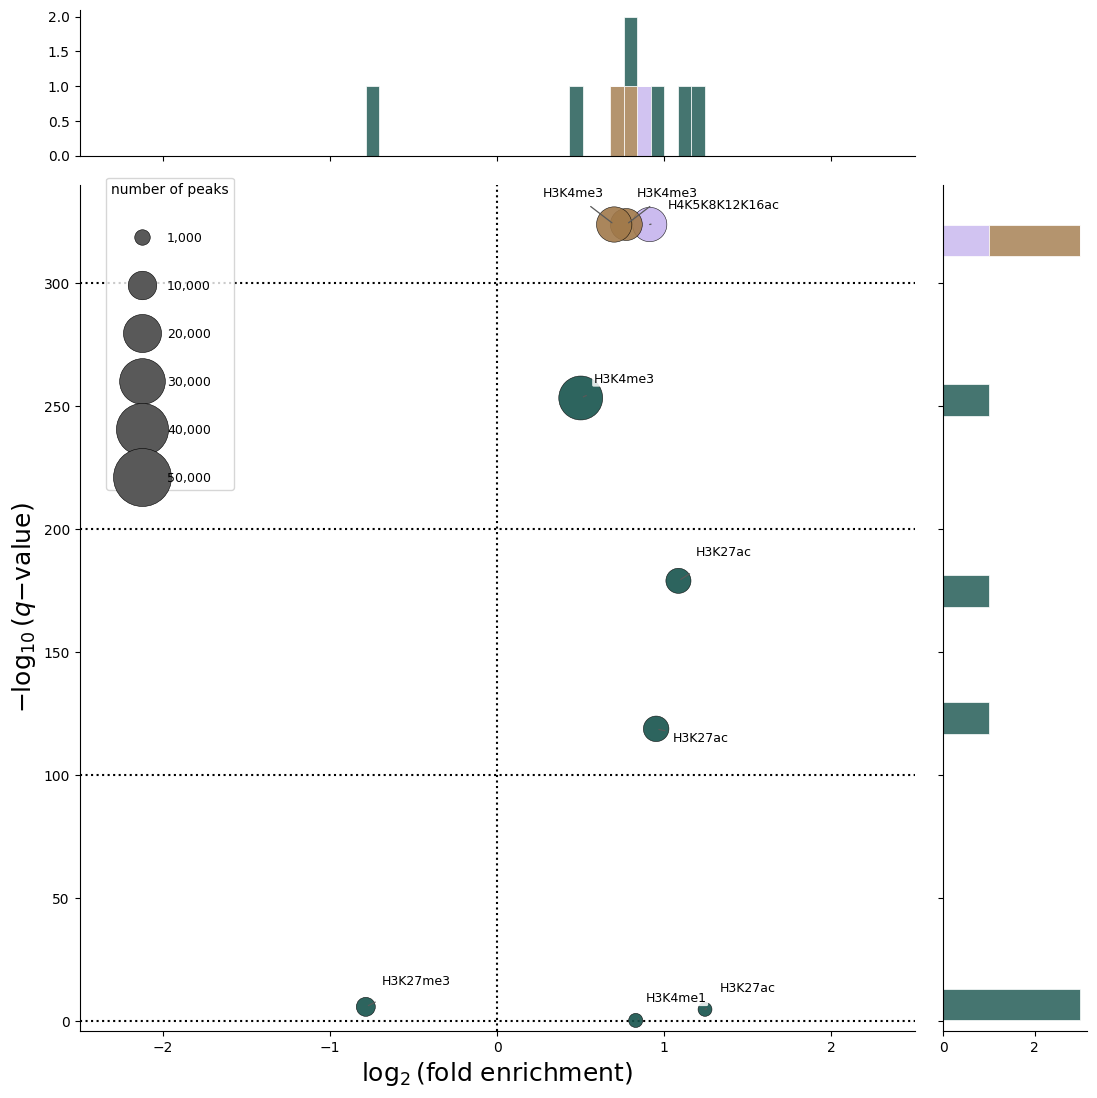

In [12]:
# =============================================================================
# Histone ChIP-seq enrichment volcano-style JointGrid (main figure)
# - Center: scatter (x = log2 fold enrichment, y = -log10 q-value)
# - Top / right: marginal histograms
# - Size legend (number of peaks) is drawn on this figure (same axes as scatter)
# - Feature labels with leader lines (adjustText) on center scatter
# - Experiment-details color legend is drawn in the NEXT cell (for slide layout)
# =============================================================================

# --- 1. Load plotting table (pandas for Seaborn) ---
histone_viz = (
    up5p_all_pla_chipseq_histone_filtered
    .unique(subset=["experiment_id"], keep="first")
    .to_pandas()
)

# --- 2. Color mapping for experiment_details (hue) ---
# Fix category order so colors stay consistent between this plot and the legend cell
experiment_labels = sorted(histone_viz["experiment_details"].unique())
palette = sns.color_palette("cubehelix", n_colors=len(experiment_labels))
experiment_colors = dict(zip(experiment_labels, palette))  # used in the next cell for the legend

# --- 3. Size mapping for num_of_peaks (bubble area) ---
SCATTER_SIZES = (100, 1000)

peaks_min = histone_viz["num_of_peaks"].min()
peaks_max = histone_viz["num_of_peaks"].max()

# Fixed legend steps (log-spaced enough to show visible size differences)
SIZE_LEGEND_VALUES = [1000, 10000, 20000, 30000, 40000, 50000]


def _peak_to_markersize(peak_val):
    # Same linear area mapping as seaborn scatterplot (sizes=SCATTER_SIZES)
    s_min, s_max = SCATTER_SIZES
    area = s_min + (peak_val - peaks_min) / (peaks_max - peaks_min) * (s_max - s_min)
    return np.sqrt(area)

# --- 4. Create JointGrid layout ---
g = sns.JointGrid(
    data=histone_viz,
    x="log2_fold_enrichment",
    y="-log10_qvalue",
    hue="experiment_details",
    palette=palette,
    hue_order=experiment_labels,
    height=11,
    ratio=5,
    marginal_ticks=True,
)

# --- 5. Center panel: bubble scatter ---
g.plot_joint(
    sns.scatterplot,
    data=histone_viz,
    size="num_of_peaks",
    sizes=SCATTER_SIZES,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --- 6. Build size-legend handles (same scaling as the scatter points above) ---
size_legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=_peak_to_markersize(v),
        markerfacecolor="0.35",
        markeredgecolor="black",
        markeredgewidth=0.4,
    )
    for v in SIZE_LEGEND_VALUES
]
size_legend_labels = [f"{v:,}" for v in SIZE_LEGEND_VALUES]

# --- 7. Marginal panels: stacked histograms by experiment_details ---
g.plot_marginals(
    sns.histplot,
    bins=25,
    multiple="stack",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
)

# --- 8. Remove any leftover legends (e.g. from histplot) ---
for ax in (g.ax_joint, g.ax_marg_x, g.ax_marg_y):
    if ax.legend_ is not None:
        ax.legend_.remove()

# --- 9. Axis limits and labels (histone panel) ---
_q_max = histone_viz["-log10_qvalue"].max()
g.ax_joint.set_xlim(-2.5, 2.5)
g.ax_joint.set_ylim(-4, max(60, _q_max * 1.05))
g.ax_joint.set_xlabel(r"$\log_{2}$(fold enrichment)", fontsize=18)
g.ax_joint.set_ylabel(r"$-\log_{10}(q\mathrm{-value})$", fontsize=18)

# --- 10. Reference lines (volcano-style guides) ---
g.ax_joint.axvline(x=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=0, color="black", linestyle=":", zorder=0)
for y_ref in (100, 200, 300):
    if y_ref <= g.ax_joint.get_ylim()[1]:
        g.ax_joint.axhline(y=y_ref, color="black", linestyle=":", zorder=0)

# --- 11. Feature labels with leader lines (adjustText + manual for tight duplicates) ---
# Bubble-sized scatter PathCollection cannot be passed as objects= in adjustText 1.4
# (its window extent returns NaN). Instead, add obstacle points around each bubble.
# Identical feature labels at nearly the same coordinates are placed manually so they
# stay close to each bubble instead of being pushed far apart by adjustText.
LABEL_OFFSET_X = 0.04
LABEL_OFFSET_Y = 4
LABEL_BBOX = dict(
    boxstyle="round,pad=0.12",
    facecolor="white",
    edgecolor="none",
    alpha=0.85,
)
LABEL_ARROW = dict(
    arrowstyle="-",
    color="0.35",
    lw=0.9,
    shrinkA=6,
    shrinkB=2,
)


def _nearby_same_feature(row, df):
    dup = df[df["feature"] == row["feature"]]
    return dup[
        (dup["-log10_qvalue"].sub(row["-log10_qvalue"]).abs() < 30)
        & (dup["log2_fold_enrichment"].sub(row["log2_fold_enrichment"]).abs() < 0.25)
    ].sort_values("log2_fold_enrichment")


def _bubble_obstacle_coords(df, peaks_min, peaks_max):
    # Approximate bubble footprint in data coordinates from num_of_peaks
    obstacle_x, obstacle_y = [], []
    for _, row in df.iterrows():
        radius_norm = (row["num_of_peaks"] - peaks_min) / (peaks_max - peaks_min)
        radius_x = 0.05 + 0.08 * radius_norm
        radius_y = 5 + 15 * radius_norm
        x0, y0 = row["log2_fold_enrichment"], row["-log10_qvalue"]
        for dx, dy in (
            (radius_x, 0), (-radius_x, 0), (0, radius_y), (0, -radius_y),
            (radius_x, radius_y), (-radius_x, -radius_y),
        ):
            obstacle_x.append(x0 + dx)
            obstacle_y.append(y0 + dy)
    return np.array(obstacle_x), np.array(obstacle_y)


_cluster_manual_idx = set()
for _idx, _row in histone_viz.iterrows():
    _nearby = _nearby_same_feature(_row, histone_viz)
    if len(_nearby) > 1:
        _cluster_manual_idx.update(_nearby.index.tolist())

for _idx, _row in histone_viz.iterrows():
    if _idx not in _cluster_manual_idx:
        continue
    _nearby = _nearby_same_feature(_row, histone_viz)
    _rank = list(_nearby.index).index(_idx)
    _n = len(_nearby)
    _x, _y = _row["log2_fold_enrichment"], _row["-log10_qvalue"]
    if _n == 2:
        if _rank == 0:
            _xytext = (_x - 0.06, _y + 10)
            _ha, _va = "right", "bottom"
        else:
            _xytext = (_x + 0.06, _y + 10)
            _ha, _va = "left", "bottom"
    else:
        _xytext = (_x + 0.04, _y + 10 + _rank * 4)
        _ha, _va = "left", "bottom"
    g.ax_joint.annotate(
        _row["feature"],
        xy=(_x, _y),
        xytext=_xytext,
        fontsize=9,
        ha=_ha,
        va=_va,
        bbox=LABEL_BBOX,
        arrowprops=LABEL_ARROW,
        zorder=6,
    )

_auto_label_df = histone_viz[~histone_viz.index.isin(_cluster_manual_idx)]
_obstacle_x, _obstacle_y = _bubble_obstacle_coords(histone_viz, peaks_min, peaks_max)
_label_repulsion_x = np.concatenate([
    histone_viz["log2_fold_enrichment"].to_numpy(),
    _obstacle_x,
])
_label_repulsion_y = np.concatenate([
    histone_viz["-log10_qvalue"].to_numpy(),
    _obstacle_y,
])

feature_label_texts = [
    g.ax_joint.text(
        row["log2_fold_enrichment"] + LABEL_OFFSET_X,
        row["-log10_qvalue"] + LABEL_OFFSET_Y,
        row["feature"],
        fontsize=9,
        ha="left",
        va="bottom",
        zorder=6,
        bbox=LABEL_BBOX,
    )
    for _, row in _auto_label_df.iterrows()
]

if feature_label_texts:
    adjust_text(
        feature_label_texts,
        x=_label_repulsion_x,
        y=_label_repulsion_y,
        target_x=_auto_label_df["log2_fold_enrichment"].to_numpy(),
        target_y=_auto_label_df["-log10_qvalue"].to_numpy(),
        ax=g.ax_joint,
        force_text=(0.35, 0.8),
        force_static=(0.45, 0.9),
        force_explode=(0.25, 0.6),
        force_pull=(0.05, 0.06),
        expand=(1.2, 1.35),
        explode_radius=120,
        max_move=(25, 45),
        pull_threshold=12,
        iter_lim=600,
        min_arrow_len=3,
        arrowprops=LABEL_ARROW,
    )

# --- 12. Size legend on the scatter axes (same point scaling as plotted bubbles) ---
leg_size = g.ax_joint.legend(
    handles=size_legend_handles,
    labels=size_legend_labels,
    title="number of peaks",
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    bbox_transform=g.ax_joint.transAxes,
    ncol=1,
    frameon=True,
    framealpha=0.8,
    labelspacing=2.8,
    handletextpad=1.0,
    borderaxespad=0.8,
    title_fontsize=10,
    fontsize=9,
)

plt.show()

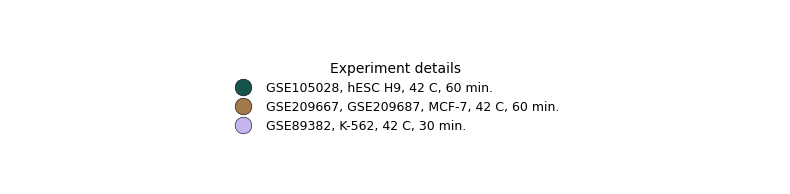

In [13]:
# --- Legend: experiment_details (color) — manual, for slide layout ---
# Size legend (number of peaks) is already on the main JointGrid figure
fig_leg_cell, ax_leg_cell = plt.subplots(figsize=(8, 0.35 * len(experiment_labels) + 1))
ax_leg_cell.axis("off")

hue_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=12,
        markerfacecolor=experiment_colors[label],
        markeredgecolor="black",
        markeredgewidth=0.4,
        label=label,
    )
    for label in experiment_labels
]

ax_leg_cell.legend(
    handles=hue_handles,
    title="Experiment details",
    loc="center",
    frameon=False,
    fontsize=9,
    title_fontsize=10,
)
fig_leg_cell.tight_layout()
# fig_leg_cell.savefig("legend_experiment_histone.pdf", bbox_inches="tight", transparent=True)

plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

---

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. HS-related ChIP-seq (RNA polymerase)

In [14]:
hs_chipseq_metadata = pl.read_csv(
    "../../Data/metadata/metadata_2608/chipseq_metadata_all_260824.tsv",
    separator='\t',
    infer_schema_length=10000
).rename(
    {
        "sample_heat_id": "experiment_id"
    }
)

pl.Config.set_tbl_rows(2)
display(hs_chipseq_metadata)

experiment_id,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_treatment_protocol_ch1,sample_growth_protocol_ch1,sample_molecule_ch1,sample_extract_protocol_ch1,sample_description,sample_data_processing,sample_platform_id,sample_contact_name,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,sample_contact_country,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_supplementary_file_1,sample_series_id,sample_data_row_count,big_key,cell_line,…,treatment1,processed_data_file,sex,tissue_cells,age,fastq_galaxy,fastq_ftp,fastq_aspera,library_strategy_right,sra_file_role,sra_aspera,sra_galaxy,sra_ftp,sample_characteristics_ch1,tumor,passages,country,collection_date,assembly,tissue,tissue_type,chip,basecalling,adapter_trimming,align,deduplication,peak_calling,batch,library_name_right,submitted_galaxy,submitted_ftp,submitted_aspera,submitted_md5,checklist,submitted_bytes,broker_name,datahub,submitted_file_role,submitted_read_type,submitted_format
str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX7107227""","""SRX7107225""","""vcap_pol2_sictrl_hs1 vs vcap_p…","""ChIP""","""Homo sapiens""","""SINGLE""","""SRA""","""multi""","""VCaP: Pol2_siCtrl_HS1 vs VCaP:…","""GSM4152129 vs GSM4152127""","""Public on Feb 05 2021""","""Nov 06 2019""","""Feb 06 2021""","""SRA""",1,"""VCaP""","""Homo sapiens""",9606,"""Heat shock for ChIP-seq sample…","""VCaP cells were grown in DMEM …","""genomic DNA""","""VCaP cells were grown in DMEM …","""resequencing of sample previou…","""ChIP-seq reads were aligned to…","""GPL18573""","""Barbara,,Hummel""","""Stübeweg 51""","""Freiburg""","""79108""","""Germany""","""Illumina NextSeq 500""","""ChIP""","""genomic""","""ChIP-Seq""","""GSM4152129 vs GSM4152127""","""ftp://ftp.ncbi.nlm.nih.gov/geo…","""GSE140053""",0,"""SRX7107227 vs SRX7107225""","""VCaP""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ERX432311""","""ERX432313""",null,null,null,null,null,"""ERR466074 vs ERR466075""","""growing_U2OS_cells_4 vs growin…",null,null,null,null,null,null,null,null,null,null,null,null,null,"""Protocols: Human osteosarcoma …",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""U2OS""",…,null,null,"""female""",null,null,"""ftp.sra.ebi.ac.uk/vol1/fastq/E…","""ftp.sra.ebi.ac.uk/vol1/fastq/E…","""fasp.sra.ebi.ac.uk:/vol1/fastq…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""ftp.sra.ebi.ac.uk/vol1/run/ERR…","""ftp.sra.ebi.ac.uk/vol1/run/ERR…","""fasp.sra.ebi.ac.uk:/vol1/run/E…","""a5bd70c326450c3a1b9d34e750bc9b…","""ERC000011""","""1680163108 vs 488437949""","""ArrayExpress""","""dcc_arrayexpress""","""SUBMISSION_FILE""","""SINGLE""","""FASTQ"""


In [15]:
up5p_all_pla_fantabio_chipseq_pol_enrichment = pl.read_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/up5p_all_cre_pla_pol.tsv",
    separator="\t",
    has_header=False,
    infer_schema_length=10000,
    new_columns=[
        "experiment_id",
        "experiment_type",
        "feature",
        "cell_class",
        "cell",
        "num_of_peaks",
        "overlaps_with_cre",
        "overlaps_with_permutation_genome_region",
        "log10_pvalue",
        "log10_qvalue",
        "fold_enrichment"
    ]
).filter(
    (pl.col("fold_enrichment") != 0) &
    (pl.col("log10_pvalue") != 0.0)
).with_columns(
    pl.col("fold_enrichment").log(base=2).alias("log2_fold_enrichment"),
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue"),
    # Parse ratio columns
    (
        pl.col("overlaps_with_cre").str.split("/").list.get(0).cast(pl.Int64) /
        pl.col("overlaps_with_cre").str.split("/").list.get(1).cast(pl.Int64)
    ).alias("overlaps_with_cre_ratio"),
).with_columns(
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue")
).drop(
    "fold_enrichment",
    "log10_pvalue",
    "log10_qvalue"
).filter(
    ((pl.col("-log10_pvalue") != -0.0) & # p-value が 算出できていない場合は除外
    (pl.col("-log10_qvalue") != -0.0)) # q-value が 算出できていない場合は除外
)

pl.Config.set_tbl_rows(10)
display(up5p_all_pla_fantabio_chipseq_pol_enrichment)

experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio
str,str,str,str,str,i64,str,str,f64,f64,f64,f64
"""SRX8030783""","""RNA polymerase""","""RNA polymerase II""","""Others""","""TC-797""",5873,"""3305/14577""","""4954/51838""",1.246372,324.0,324.0,0.226727
"""SRX1136642""","""RNA polymerase""","""RNA polymerase II""","""Uterus""","""HeLa""",4883,"""3268/14577""","""4967/51838""",1.226348,324.0,324.0,0.224189
"""SRX6637045""","""RNA polymerase""","""RNA polymerase II""","""Breast""","""MCF 10A""",5002,"""3754/14577""","""5728/51838""",1.220714,324.0,324.0,0.257529
"""SRX4385538""","""RNA polymerase""","""RNA polymerase II""","""Digestive tract""","""HCT 116""",5167,"""4032/14577""","""6330/51838""",1.179607,324.0,324.0,0.2766
"""SRX6637050""","""RNA polymerase""","""RNA polymerase II""","""Breast""","""MCF 10A""",6453,"""4593/14577""","""7284/51838""",1.165024,324.0,324.0,0.315085
…,…,…,…,…,…,…,…,…,…,…,…
"""SRX11325330""","""RNA polymerase""","""RNA polymerase II""","""Breast""","""Breast cancer cells""",119,"""5/14577""","""22/51838""",-0.307187,0.0871931,0.0790538,0.000343
"""SRX1748271""","""RNA polymerase""","""RNA polymerase II""","""Blood""","""NALM-6""",167,"""7/14577""","""22/51838""",0.178237,0.0850372,0.0770032,0.00048
"""SRX8902534""","""RNA polymerase""","""RNA polymerase II""","""Blood""","""Erythroid Cells""",820,"""6/14577""","""25/51838""",-0.228578,0.0802131,0.0722844,0.000412


In [16]:
up5p_all_pla_chipseq_pol_filtered = up5p_all_pla_fantabio_chipseq_pol_enrichment.join(
    hs_chipseq_metadata,
    on="experiment_id",
    how="inner"
).unique(subset=["experiment_id"], keep="first").sort(
    by=["-log10_qvalue", "log2_fold_enrichment"],
    descending=[True, True],
).with_columns(
    pl.concat_str(
        [
            pl.col("sample_series_id"),
            pl.col("cell"),
            pl.col("stress treatment temperature"),
            pl.col("stress treatment time"),
        ],
        separator=", ",  # delimiter between fields
        ignore_nulls=True,  # skip null values instead of propagating null
    ).alias("experiment_details")
)

# 念のため保存する
up5p_all_pla_chipseq_pol_filtered.write_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/filtered/up5p_all_cre_pla_pol_filtered.tsv",
    separator="\t",
    include_header=True
)

print(up5p_all_pla_chipseq_pol_filtered.select("feature").unique()) # RNA polymerase II だけなのか確かめるss
print(f"HS-related RNA polymerase ChIP-seq experiments: {up5p_all_pla_chipseq_pol_filtered.select('experiment_id').n_unique()}")
display(up5p_all_pla_chipseq_pol_filtered)

shape: (1, 1)
┌───────────────────┐
│ feature           │
│ ---               │
│ str               │
╞═══════════════════╡
│ RNA polymerase II │
└───────────────────┘
HS-related RNA polymerase ChIP-seq experiments: 63


experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_treatment_protocol_ch1,sample_growth_protocol_ch1,sample_molecule_ch1,sample_extract_protocol_ch1,sample_description,sample_data_processing,sample_platform_id,sample_contact_name,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,…,processed_data_file,sex,tissue_cells,age,fastq_galaxy,fastq_ftp,fastq_aspera,library_strategy_right,sra_file_role,sra_aspera,sra_galaxy,sra_ftp,sample_characteristics_ch1,tumor,passages,country,collection_date,assembly,tissue,tissue_type,chip,basecalling,adapter_trimming,align,deduplication,peak_calling,batch,library_name_right,submitted_galaxy,submitted_ftp,submitted_aspera,submitted_md5,checklist,submitted_bytes,broker_name,datahub,submitted_file_role,submitted_read_type,submitted_format,experiment_details
str,str,str,str,str,i64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX7551113""","""RNA polymerase""","""RNA polymerase II""","""Uterus""","""HeLa""",12629,"""8165/14577""","""15088/51838""",0.944439,324.0,324.0,0.560129,"""SRX7551110""","""zd6_heatshock_pol2 vs zd3_untr…","""ChIP""","""Homo sapiens""","""SINGLE""","""SRA""","""SRR10882049 vs SRR10882046""","""Zd6_Heatshock_Pol2 vs Zd3_Untr…","""GSM4263568 vs GSM4263565""","""Public on Jan 13 2021""","""Jan 13 2020""","""Jan 14 2021""","""SRA""",1,"""HeLa cell""","""Homo sapiens""",9606,null,null,"""genomic DNA""",null,"""Zd6_Heatshock_Pol2 vs Zd3_Untr…",null,"""GPL18573""","""Rosemary,,Kiernan""","""141 rue de la cardonille""","""Montpellier""","""34396""",…,null,null,null,null,"""ftp.sra.ebi.ac.uk/vol1/fastq/S…","""ftp.sra.ebi.ac.uk/vol1/fastq/S…","""fasp.sra.ebi.ac.uk:/vol1/fastq…",null,null,null,null,null,null,null,"""13-15""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""GSE143591, HeLa, 42 C, 60 min."""
"""SRX16646106""","""RNA polymerase""","""RNA polymerase II""","""Breast""","""MCF-7""",11232,"""8881/14577""","""16448/51838""",0.941196,324.0,324.0,0.609247,"""SRX16646105""","""mcf7_hs_rna_pol_ii_rep_2 vs mc…",null,null,null,null,"""SRR20622356 vs SRR20622357""","""MCF7 HS RNA Pol II rep 2 vs MC…","""GSM6383092 vs GSM6383091""","""Public on Oct 30 2023""","""Jul 25 2022""","""Oct 30 2023""","""SRA""",1,"""MCF7""","""Homo sapiens""",9606,null,null,"""genomic DNA""",null,"""MCF7 HS RNA Pol II rep 2 vs MC…","""Raw files were adapter-trimmed…","""GPL20301""","""Sergei,,Nechaev""",null,"""Grand Forks""","""58202""",…,null,null,null,null,"""ftp.sra.ebi.ac.uk/vol1/fastq/S…","""ftp.sra.ebi.ac.uk/vol1/fastq/S…","""fasp.sra.ebi.ac.uk:/vol1/fastq…",null,null,null,null,null,null,null,null,"""missing""","""missing""","""hg19""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""GSE209667, GSE209687, MCF-7, 4…"
"""SRX7748733""","""RNA polymerase""","""RNA polymerase II""","""Digestive tract""","""DLD-1""",11681,"""7401/14577""","""13945/51838""",0.916362,324.0,324.0,0.507718,"""SRX7748732""","""2haux_42c1h_pol2cst_doubleaid_…","""ChIP""","""Homo sapiens""","""SINGLE""","""SRA""","""SRR11111713 vs SRR11111712""","""2hAux_42C1h_Pol2CST_DoubleAID_…","""GSM4320238 vs GSM4320237""","""Public on Jan 15 2021""","""Feb 19 2020""","""Jan 16 2021""","""SRA""",1,"""DLD-1""","""Homo sapie

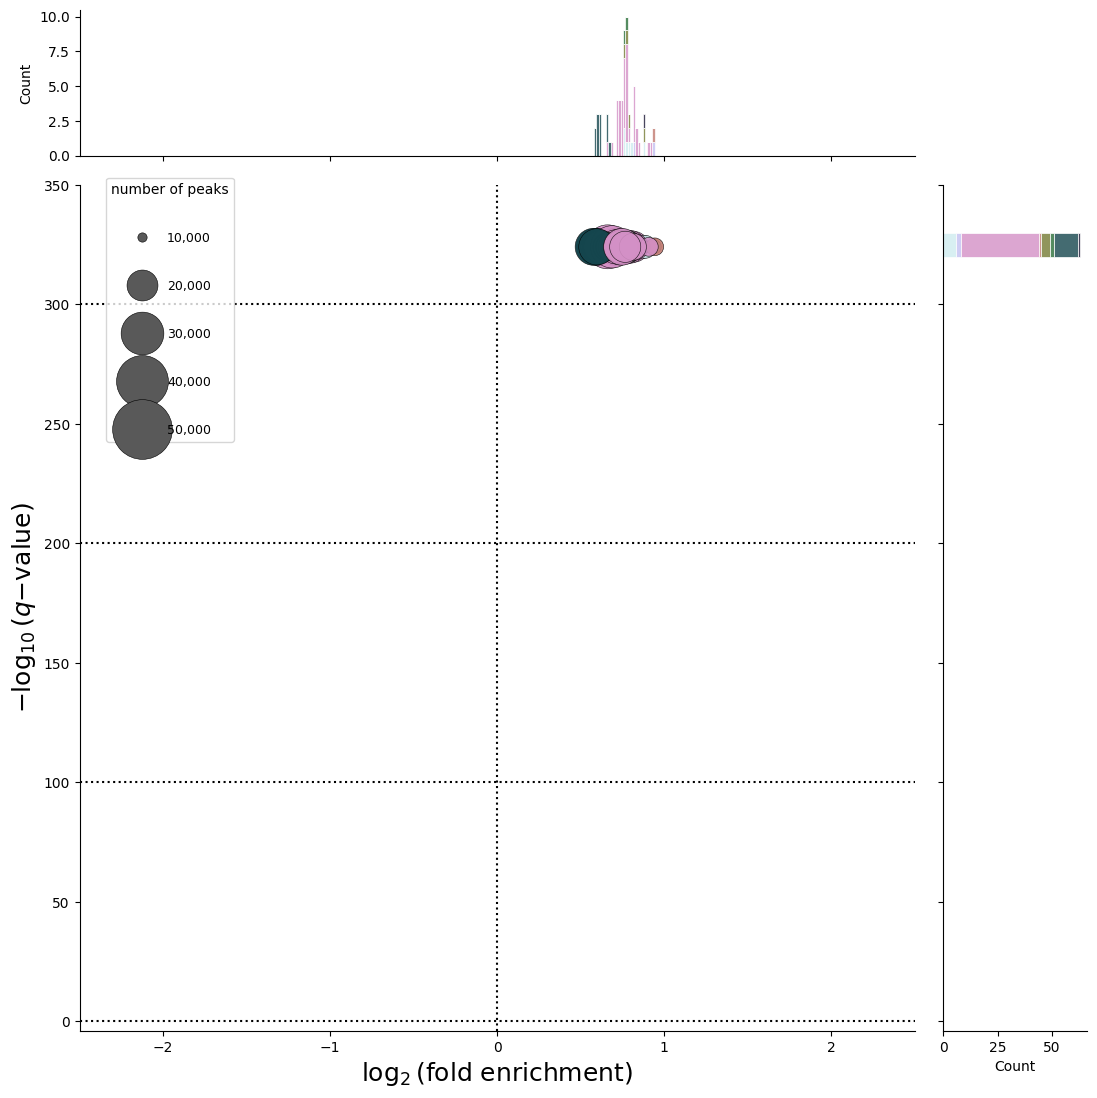

In [17]:
# =============================================================================
# RNA polymerase ChIP-seq enrichment volcano-style JointGrid (main figure)
# - Center: scatter (x = log2 fold enrichment, y = -log10 q-value)
# - Top / right: marginal histograms
# - Size legend (number of peaks) is drawn on this figure (same axes as scatter)
# - The shared feature name is shown once on the center scatter
# - Cell-line color legend is drawn in the NEXT cell (for slide layout)
# =============================================================================

# --- 1. Load plotting table (pandas for Seaborn) ---
# Keep one row per experiment before plotting
pol_viz = (
    up5p_all_pla_chipseq_pol_filtered
    .unique(subset=["experiment_id"], keep="first")
    .to_pandas()
)

# --- 2. Color mapping for cell line (hue) ---
# Fix category order so colors stay consistent between this plot and the legend cell
cells = sorted(pol_viz["experiment_details"].unique())
palette = sns.color_palette("cubehelix", n_colors=len(cells))
cell_colors = dict(zip(cells, palette))  # used in the next cell for the cell-line legend

# --- 3. Size mapping for num_of_peaks (bubble area) ---
# Min/max marker area in points^2; Seaborn scales num_of_peaks linearly between these
SCATTER_SIZES = (100, 1000)

peaks_min = pol_viz["num_of_peaks"].min()
peaks_max = pol_viz["num_of_peaks"].max()

# Use legend values that match the RNAP peak-count range
SIZE_LEGEND_VALUES = [10000, 20000, 30000, 40000, 50000]


def _peak_to_markersize(peak_val):
    # Same linear area mapping as seaborn scatterplot (sizes=SCATTER_SIZES)
    s_min, s_max = SCATTER_SIZES
    area = s_min + (peak_val - peaks_min) / (peaks_max - peaks_min) * (s_max - s_min)
    return np.sqrt(area)

# --- 4. Create JointGrid layout ---
# Hue is set here; size is set in plot_joint below
g = sns.JointGrid(
    data=pol_viz,
    x="log2_fold_enrichment",
    y="-log10_qvalue",
    hue="experiment_details",
    palette=palette,
    hue_order=cells,
    height=11,
    ratio=5,
    marginal_ticks=True,
)

# --- 5. Center panel: bubble scatter ---
g.plot_joint(
    sns.scatterplot,
    data=pol_viz,
    size="num_of_peaks",
    sizes=SCATTER_SIZES,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --- 6. Build size-legend handles (same scaling as the scatter points above) ---
size_legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=_peak_to_markersize(v),
        markerfacecolor="0.35",
        markeredgecolor="black",
        markeredgewidth=0.4,
    )
    for v in SIZE_LEGEND_VALUES
]
size_legend_labels = [f"{v:,}" for v in SIZE_LEGEND_VALUES]

# --- 7. Marginal panels: stacked histograms by cell line ---
# Draw each marginal separately so the constant q-value gets a visible bin
sns.histplot(
    data=pol_viz,
    x="log2_fold_enrichment",
    hue="experiment_details",
    hue_order=cells,
    palette=palette,
    bins=25,
    multiple="stack",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
    ax=g.ax_marg_x,
)

sns.histplot(
    data=pol_viz,
    y="-log10_qvalue",
    hue="experiment_details",
    hue_order=cells,
    palette=palette,
    binwidth=10,
    binrange=(-4, 350),
    multiple="stack",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
    ax=g.ax_marg_y,
)

# --- 8. Remove any leftover legends (e.g. from histplot) ---
for ax in (g.ax_joint, g.ax_marg_x, g.ax_marg_y):
    if ax.legend_ is not None:
        ax.legend_.remove()

# --- 9. Axis limits and labels ---
g.ax_joint.set_xlim(-2.5, 2.5)
g.ax_joint.set_ylim(-4, 350)
g.ax_joint.set_xlabel(r"$\log_{2}$(fold enrichment)", fontsize=18)
g.ax_joint.set_ylabel(r"$-\log_{10}(q\mathrm{-value})$", fontsize=18)

# --- 10. Reference lines (volcano-style guides) ---
# x = 0 means fold enrichment = 1 (no change on the log2 scale)
g.ax_joint.axvline(x=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=100, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=200, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=300, color="black", linestyle=":", zorder=0)

# --- 12. Size legend on the scatter axes (same point scaling as plotted bubbles) ---
# loc="upper left" anchors the legend's top-left corner at bbox_to_anchor
leg_size = g.ax_joint.legend(
    handles=size_legend_handles,
    labels=size_legend_labels,
    title="number of peaks",
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    bbox_transform=g.ax_joint.transAxes,
    ncol=1,
    frameon=True,
    framealpha=0.8,
    labelspacing=2.8,
    handletextpad=1.0,
    borderaxespad=0.8,
    title_fontsize=10,
    fontsize=9,
)

plt.show()

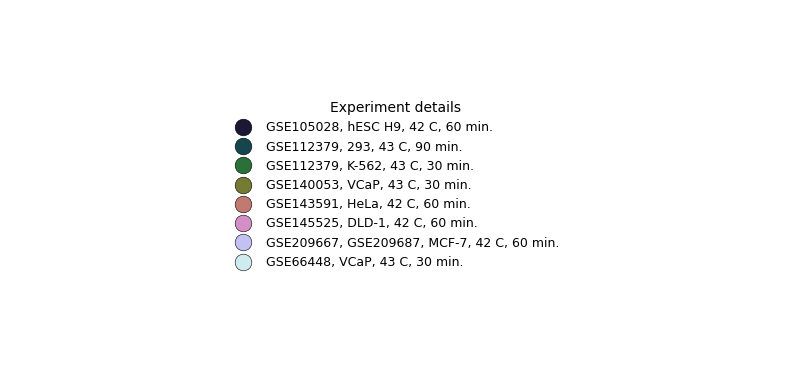

In [18]:
# --- Legend: cell line (color) — manual, for slide layout ---
# Size legend (number of peaks) is already on the main JointGrid figure
fig_leg_cell, ax_leg_cell = plt.subplots(figsize=(8, 0.35 * len(cells) + 1))
ax_leg_cell.axis("off")

hue_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=12,
        markerfacecolor=cell_colors[cell],
        markeredgecolor="black",
        markeredgewidth=0.4,
        label=cell,
    )
    for cell in cells
]

ax_leg_cell.legend(
    handles=hue_handles,
    title="Experiment details",
    loc="center",
    frameon=False,
    fontsize=9,
    title_fontsize=10,
)
fig_leg_cell.tight_layout()
# fig_leg_cell.savefig("legend_cell_rnap.pdf", bbox_inches="tight", transparent=True)

plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. TFs and Others (HSF1)

- ChIP-Atlas のメタデータ (`feature column`) が間違っているケースが含まれていたので確認する

### incorrect metadata

- [Architectural Proteins and Pluripotency Factors Cooperate to Orchestrate the Transcriptional Response of hESCs to Temperature Stress](https://doi.org/10.1016/j.molcel.2018.07.012) に関連したデータ

1. [SRX3288573](https://chip-atlas.org/view?id=SRX3288573) RNF2 → RING1B (correct antigen)
2. [SRX3288571](https://chip-atlas.org/view?id=SRX3288571) POU5F1 → OCT4 (correct antigen)


In [20]:
up5p_all_pla_fantabio_chipseq_tf_enrichment = pl.read_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/up5p_all_cre_pla_tf.tsv",
    separator="\t",
    has_header=False,
    infer_schema_length=10000,
    new_columns=[
        "experiment_id",
        "experiment_type",
        "feature",
        "cell_class",
        "cell",
        "num_of_peaks",
        "overlaps_with_cre",
        "overlaps_with_permutation_genome_region",
        "log10_pvalue",
        "log10_qvalue",
        "fold_enrichment"
    ]
).filter(
    (pl.col("fold_enrichment") != 0) &
    (pl.col("log10_pvalue") != 0.0)
).with_columns(
    pl.col("fold_enrichment").log(base=2).alias("log2_fold_enrichment"),
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue"),
    # Parse ratio columns
    (
        pl.col("overlaps_with_cre").str.split("/").list.get(0).cast(pl.Int64) /
        pl.col("overlaps_with_cre").str.split("/").list.get(1).cast(pl.Int64)
    ).alias("overlaps_with_cre_ratio"),
).with_columns(
    pl.col("log10_pvalue").neg().alias("-log10_pvalue"),
    pl.col("log10_qvalue").neg().alias("-log10_qvalue")
).drop(
    "fold_enrichment",
    "log10_pvalue",
    "log10_qvalue"
)

pl.Config.set_tbl_rows(10)
display(up5p_all_pla_fantabio_chipseq_tf_enrichment)

experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio
str,str,str,str,str,i64,str,str,f64,f64,f64,f64
"""SRX19888696""","""TFs and others""","""NELFE""","""Breast""","""BT-549""",4363,"""3198/14577""","""4790/51838""",1.24746,324.0,324.0,0.219387
"""SRX2510812""","""TFs and others""","""NELFA""","""Uterus""","""HeLa""",5374,"""4205/14577""","""6580/51838""",1.184337,324.0,324.0,0.288468
"""SRX1758494""","""TFs and others""","""NELFE""","""Breast""","""MCF-7""",5493,"""3978/14577""","""6257/51838""",1.176891,324.0,324.0,0.272896
"""SRX1758496""","""TFs and others""","""NELFE""","""Breast""","""MCF-7""",5559,"""4106/14577""","""6463/51838""",1.175844,324.0,324.0,0.281677
"""SRX1758493""","""TFs and others""","""NELFE""","""Breast""","""MCF-7""",6276,"""4514/14577""","""7262/51838""",1.144353,324.0,324.0,0.309666
…,…,…,…,…,…,…,…,…,…,…,…
"""SRX7959859""","""TFs and others""","""RAD21""","""Uterus""","""HEC-1-B""",17462,"""478/14577""","""1698/51838""",0.001557,0.009219,-0.0,0.032791
"""SRX3734314""","""TFs and others""","""TP63""","""Breast""","""Mammary glands""",24519,"""486/14577""","""1734/51838""",-0.00476,0.009131,-0.0,0.03334
"""SRX5286326""","""TFs and others""","""NANOG""","""Pluripotent stem cell""","""hESC WIBR2""",42120,"""554/14577""","""1969/51838""",0.000808,0.008578,-0.0,0.038005


In [22]:
up5p_all_pla_chipseq_tf_filtered = up5p_all_pla_fantabio_chipseq_tf_enrichment.join(
    hs_chipseq_metadata,
    on="experiment_id",
    how="inner"
).unique(subset=["experiment_id"], keep="first").sort(
    by=["-log10_qvalue", "log2_fold_enrichment"],
    descending=[True, True],
).with_columns(
    # メタデータが間違っているケースをここで修正
    pl.when(pl.col("experiment_id") == "SRX3288573").then(pl.lit("RING1B")) # RNF2 → RING1B
    .when(pl.col("experiment_id") == "SRX3288571").then(pl.lit("OCT4")) # POU5F1 → OCT4
    .otherwise(pl.col("feature"))
    .alias("feature")
).with_columns(
    pl.concat_str(
        [
            pl.col("sample_series_id"),
            pl.col("cell"),
            pl.col("stress treatment temperature"),
            pl.col("stress treatment time"),
            pl.col("feature") # add feature name
        ],
        separator=", ",  # delimiter between fields
        ignore_nulls=True,  # skip null values instead of propagating null
    ).alias("experiment_details")
).sort(
    by=["log2_fold_enrichment"],
    descending=[True],
)

# 念のため保存する
up5p_all_pla_chipseq_tf_filtered.write_csv(
    "../../out/ChIP-Atlas_enrichment/up5p_all_pla_202609_v5_gncd_linked/filtered/up5p_all_cre_pla_tf_filtered.tsv",
    separator="\t",
    include_header=True
)

pl.Config.set_tbl_rows(4)
pl.Config.set_tbl_cols(200)
print(up5p_all_pla_chipseq_tf_filtered.select("feature").unique()) # どのTFが含まれているか確認
print(f"TF and Others ChIP-seq experiments: {up5p_all_pla_chipseq_tf_filtered.select('experiment_id').n_unique()}")
display(up5p_all_pla_chipseq_tf_filtered)

shape: (22, 1)
┌─────────┐
│ feature │
│ ---     │
│ str     │
╞═════════╡
│ KDM3A   │
│ WAPL    │
│ …       │
│ NELFA   │
│ MAPK14  │
└─────────┘
TF and Others ChIP-seq experiments: 64


experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_treatment_protocol_ch1,sample_growth_protocol_ch1,sample_molecule_ch1,sample_extract_protocol_ch1,sample_description,sample_data_processing,sample_platform_id,sample_contact_name,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,sample_contact_country,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_supplementary_file_1,sample_series_id,sample_data_row_count,big_key,cell_line,chip_antibody,treatment,condition,genome_build,alternative_to,biosample,sra,sample_accession,reference_doi,stress treatment temperature,stress treatment time,control treatment temperature,sample_contact_email,sample_contact_laboratory,sample_contact_department,sample_contact_state,genotype,experiment_title,project_name,submission_accession,library_selection,last_updated,sra_bytes,fastq_bytes,instrument_platform,ncbi_reporting_standard,sample_description_right,fastq_md5,secondary_study_accession,read_count,study_title,sample_title_right,instrument_model,description,sra_md5,base_count,library_strategy,library_source,library_layout,status,sample_alias,run_alias,library_construction_protocol,experiment_alias,center_name,cell_line_right,first_created,study_accession,accession,secondary_sample_accession,first_public,study_alias,sample_contact_institute,cell_type,antibody,tumorigenic_or_nontumorigenic,42˚_c_1h_heat-shock_,fastq_file_role,cell_type_right,tax_lineage,library_name,tag,scientific_name,tax_id,sample_contact_phone,sample_supplementary_file_2,cell_cycle_phase,antibody_manufacturer,supplementary_files_format_and_content,treatment1,processed_data_file,sex,tissue_cells,age,fastq_galaxy,fastq_ftp,fastq_aspera,library_strategy_right,sra_file_role,sra_aspera,sra_galaxy,sra_ftp,sample_characteristics_ch1,tumor,passages,country,collection_date,assembly,tissue,tissue_type,chip,basecalling,adapter_trimming,align,deduplication,peak_calling,batch,library_name_right,submitted_galaxy,submitted_ftp,submitted_aspera,submitted_md5,checklist,submitted_bytes,broker_name,datahub,submitted_file_role,submitted_read_type,submitted_format,experiment_details
str,str,str,str,str,i64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX8512780""","""TFs and others""","""HSF1""","""Digestive tract""","""HCT 116""",343,"""61/14577""","""69/51838""",1.652528,9.46295,8.98544,0.004185,"""SRX8512779""","""hsf1_1a9_43 vs hsf1_1a9_37""","""ChIP""","""Homo sapiens""","""SINGLE""","""SRA""","""SRR11969000 vs SRR11968999""","""HSF1_1A9_43 vs HSF1_1A9_37""","""GSM4604722 vs GSM4604721""","""Public on Sep 01 2020""","""Jun 09 2020""","""Sep 02 2020""","""SRA""",1,"""HCT116""","""Homo sapiens""",9606,null,null,"""genomic DNA""",null,"""HSF1_1A9_43 vs HSF1_1A9_37""",null,"""GPL18573""","""Ali,,Shilatifard""","""320 E Superior St""","""Chicago""","""60611""","""USA""","""Illumina NextSeq 500""","""ChIP""","""genomic""","""ChIP-Seq""","""GSM4604722 vs GSM4604721""","""ftp://ftp.ncbi.

In [23]:
up5p_all_pla_chipseq_tf_filtered_hsf1 = up5p_all_pla_chipseq_tf_filtered.filter(
    pl.col("feature") == "HSF1"
)


print(up5p_all_pla_chipseq_tf_filtered_hsf1.select("experiment_id").n_unique())
display(up5p_all_pla_chipseq_tf_filtered_hsf1)

24


experiment_id,experiment_type,feature,cell_class,cell,num_of_peaks,overlaps_with_cre,overlaps_with_permutation_genome_region,log2_fold_enrichment,-log10_pvalue,-log10_qvalue,overlaps_with_cre_ratio,sample_control_id,sample_name,protocol,organism,read_type,data_source,run_accession,sample_title,sample_geo_accession,sample_status,sample_submission_date,sample_last_update_date,sample_type,sample_channel_count,sample_source_name_ch1,sample_organism_ch1,sample_taxid_ch1,sample_treatment_protocol_ch1,sample_growth_protocol_ch1,sample_molecule_ch1,sample_extract_protocol_ch1,sample_description,sample_data_processing,sample_platform_id,sample_contact_name,sample_contact_address,sample_contact_city,sample_contact_zip_postal_code,sample_contact_country,sample_instrument_model,sample_library_selection,sample_library_source,sample_library_strategy,gsm_id,sample_supplementary_file_1,sample_series_id,sample_data_row_count,big_key,cell_line,chip_antibody,treatment,condition,genome_build,alternative_to,biosample,sra,sample_accession,reference_doi,stress treatment temperature,stress treatment time,control treatment temperature,sample_contact_email,sample_contact_laboratory,sample_contact_department,sample_contact_state,genotype,experiment_title,project_name,submission_accession,library_selection,last_updated,sra_bytes,fastq_bytes,instrument_platform,ncbi_reporting_standard,sample_description_right,fastq_md5,secondary_study_accession,read_count,study_title,sample_title_right,instrument_model,description,sra_md5,base_count,library_strategy,library_source,library_layout,status,sample_alias,run_alias,library_construction_protocol,experiment_alias,center_name,cell_line_right,first_created,study_accession,accession,secondary_sample_accession,first_public,study_alias,sample_contact_institute,cell_type,antibody,tumorigenic_or_nontumorigenic,42˚_c_1h_heat-shock_,fastq_file_role,cell_type_right,tax_lineage,library_name,tag,scientific_name,tax_id,sample_contact_phone,sample_supplementary_file_2,cell_cycle_phase,antibody_manufacturer,supplementary_files_format_and_content,treatment1,processed_data_file,sex,tissue_cells,age,fastq_galaxy,fastq_ftp,fastq_aspera,library_strategy_right,sra_file_role,sra_aspera,sra_galaxy,sra_ftp,sample_characteristics_ch1,tumor,passages,country,collection_date,assembly,tissue,tissue_type,chip,basecalling,adapter_trimming,align,deduplication,peak_calling,batch,library_name_right,submitted_galaxy,submitted_ftp,submitted_aspera,submitted_md5,checklist,submitted_bytes,broker_name,datahub,submitted_file_role,submitted_read_type,submitted_format,experiment_details
str,str,str,str,str,i64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""SRX8512780""","""TFs and others""","""HSF1""","""Digestive tract""","""HCT 116""",343,"""61/14577""","""69/51838""",1.652528,9.46295,8.98544,0.004185,"""SRX8512779""","""hsf1_1a9_43 vs hsf1_1a9_37""","""ChIP""","""Homo sapiens""","""SINGLE""","""SRA""","""SRR11969000 vs SRR11968999""","""HSF1_1A9_43 vs HSF1_1A9_37""","""GSM4604722 vs GSM4604721""","""Public on Sep 01 2020""","""Jun 09 2020""","""Sep 02 2020""","""SRA""",1,"""HCT116""","""Homo sapiens""",9606,null,null,"""genomic DNA""",null,"""HSF1_1A9_43 vs HSF1_1A9_37""",null,"""GPL18573""","""Ali,,Shilatifard""","""320 E Superior St""","""Chicago""","""60611""","""USA""","""Illumina NextSeq 500""","""ChIP""","""genomic""","""ChIP-Seq""","""GSM4604722 vs GSM4604721""","""ftp://ftp.ncbi.

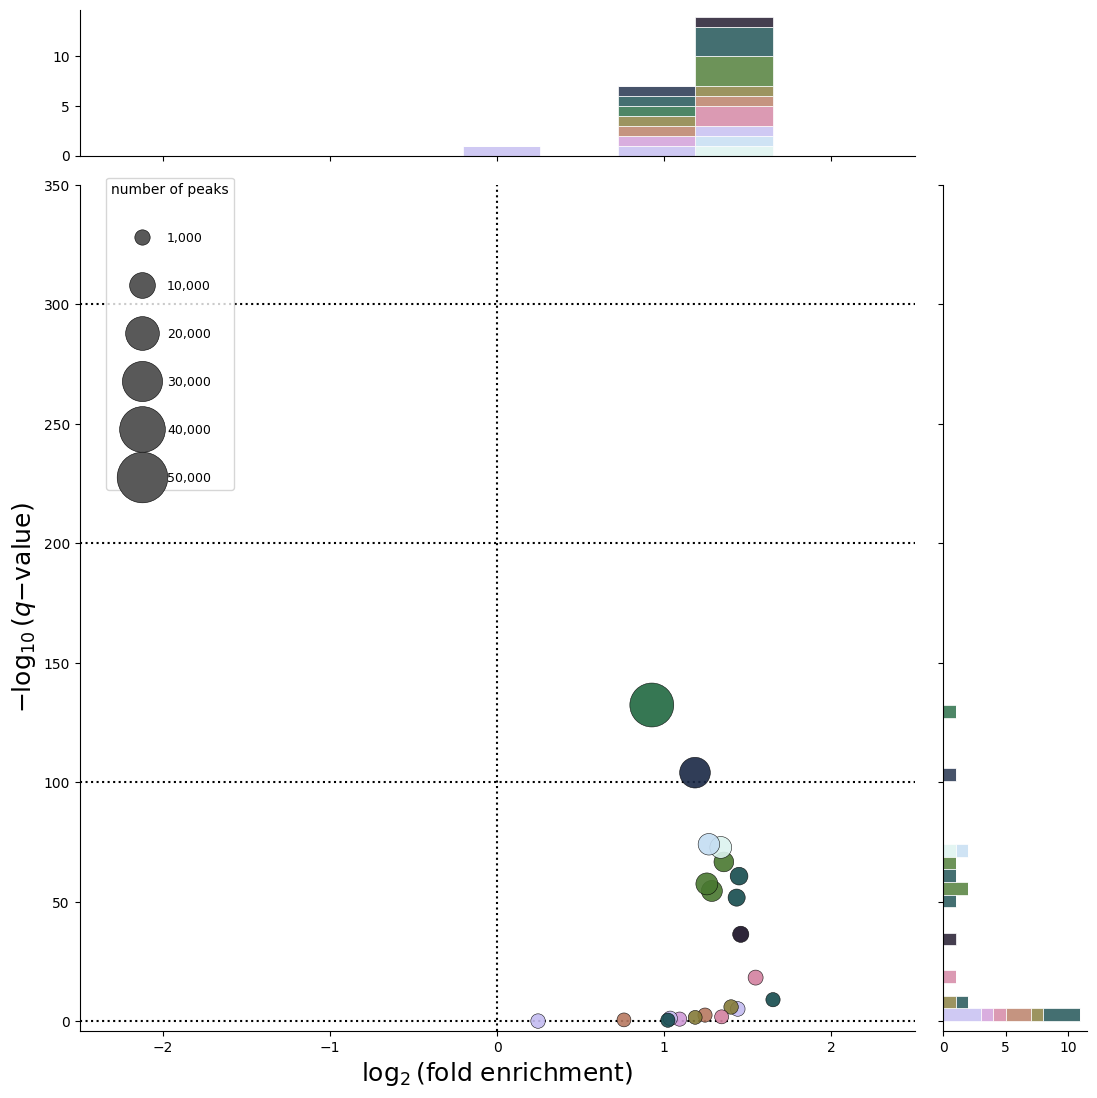

In [24]:
# =============================================================================
# HSF1 ChIP-seq enrichment volcano-style JointGrid (main figure)
# - Center: scatter (x = log2 fold enrichment, y = -log10 q-value)
# - Top / right: marginal histograms
# - Size legend (number of peaks) is drawn on this figure (same axes as scatter)
# - Cell-line color legend is drawn in the NEXT cell (for slide layout)
# =============================================================================

# --- 1. Load plotting table (pandas for Seaborn) ---
tf_hsf1_viz = up5p_all_pla_chipseq_tf_filtered_hsf1.to_pandas()

# --- 2. Color mapping for cell line (hue) ---
cells = sorted(tf_hsf1_viz["experiment_details"].unique())
palette = sns.color_palette("cubehelix", n_colors=len(cells))
cell_colors = dict(zip(cells, palette))  # used in the next cell for the cell-line legend

# --- 3. Size mapping for num_of_peaks (bubble area) ---
SCATTER_SIZES = (100, 1000)

peaks_min = tf_hsf1_viz["num_of_peaks"].min()
peaks_max = tf_hsf1_viz["num_of_peaks"].max()

# Fixed legend steps (log-spaced enough to show visible size differences)
SIZE_LEGEND_VALUES = [1000, 10000, 20000, 30000, 40000, 50000]


def _peak_to_markersize(peak_val):
    # Same linear area mapping as seaborn scatterplot (sizes=SCATTER_SIZES)
    s_min, s_max = SCATTER_SIZES
    area = s_min + (peak_val - peaks_min) / (peaks_max - peaks_min) * (s_max - s_min)
    return np.sqrt(area)

# --- 4. Create JointGrid layout ---
g = sns.JointGrid(
    data=tf_hsf1_viz,
    x="log2_fold_enrichment",
    y="-log10_qvalue",
    hue="experiment_details",
    palette=palette,
    hue_order=cells,
    height=11,
    ratio=5,
    marginal_ticks=True,
)

# --- 5. Center panel: bubble scatter ---
g.plot_joint(
    sns.scatterplot,
    data=tf_hsf1_viz,
    size="num_of_peaks",
    sizes=SCATTER_SIZES,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --- 6. Build size-legend handles (same scaling as the scatter points above) ---
size_legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=_peak_to_markersize(v),
        markerfacecolor="0.35",
        markeredgecolor="black",
        markeredgewidth=0.4,
    )
    for v in SIZE_LEGEND_VALUES
]
size_legend_labels = [f"{v:,}" for v in SIZE_LEGEND_VALUES]

# --- 7. Marginal panels: stacked histograms by cell line ---
g.plot_marginals(
    sns.histplot,
    bins=25,
    multiple="stack",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
)

# --- 8. Remove any leftover legends (e.g. from histplot) ---
for ax in (g.ax_joint, g.ax_marg_x, g.ax_marg_y):
    if ax.legend_ is not None:
        ax.legend_.remove()

# --- 9. Axis limits and labels (histone panel) ---
_q_max = tf_hsf1_viz["-log10_qvalue"].max()
g.ax_joint.set_xlim(-2.5, 2.5)
g.ax_joint.set_ylim(-4, 350)
g.ax_joint.set_xlabel(r"$\log_{2}$(fold enrichment)", fontsize=18)
g.ax_joint.set_ylabel(r"$-\log_{10}(q\mathrm{-value})$", fontsize=18)

# --- 10. Reference lines (volcano-style guides) ---
g.ax_joint.axvline(x=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=0, color="black", linestyle=":", zorder=0)
for y_ref in (100, 200, 300):
    if y_ref <= g.ax_joint.get_ylim()[1]:
        g.ax_joint.axhline(y=y_ref, color="black", linestyle=":", zorder=0)

# --- 11. Size legend on the scatter axes (same point scaling as plotted bubbles) ---
leg_size = g.ax_joint.legend(
    handles=size_legend_handles,
    labels=size_legend_labels,
    title="number of peaks",
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    bbox_transform=g.ax_joint.transAxes,
    ncol=1,
    frameon=True,
    framealpha=0.8,
    labelspacing=2.8,
    handletextpad=1.0,
    borderaxespad=0.8,
    title_fontsize=10,
    fontsize=9,
)

plt.show()

In [ ]:
# --- Legend: cell line (color) — manual, for slide layout ---
# Size legend (number of peaks) is already on the main JointGrid figure
fig_leg_cell, ax_leg_cell = plt.subplots(figsize=(3, 2))
ax_leg_cell.axis("off")

hue_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=12,
        markerfacecolor=cell_colors[cell],
        markeredgecolor="black",
        markeredgewidth=0.4,
        label=cell,
    )
    for cell in cells
]

ax_leg_cell.legend(
    handles=hue_handles,
    title="Experiment details",
    loc="center",
    frameon=False,
)
fig_leg_cell.tight_layout()
# fig_leg_cell.savefig("legend_cell_histone.pdf", bbox_inches="tight", transparent=True)

plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. TFs and Others (Other)

In [ ]:
up5p_all_pla_chipseq_tf_filtered_other = up5p_all_pla_chipseq_tf_filtered.filter(
    pl.col("feature") != "HSF1"
)


print(up5p_all_pla_chipseq_tf_filtered_other.select("experiment_id").n_unique())
display(up5p_all_pla_chipseq_tf_filtered_other)

In [ ]:
# =============================================================================
# Other TF ChIP-seq enrichment volcano-style JointGrid (main figure)
# - Center: scatter (x = log2 fold enrichment, y = -log10 q-value)
# - Top / right: marginal histograms
# - Size legend (number of peaks) is drawn on this figure (same axes as scatter)
# - experiment_details already includes feature name upstream
# - Experiment-details and transcription-factor legends are drawn in the NEXT cell
# =============================================================================

# --- 1. Load plotting table (pandas for Seaborn) ---
tf_other_viz = up5p_all_pla_chipseq_tf_filtered_other.to_pandas()

# --- 2. Color mapping for experiment_details (hue) ---
cells = sorted(tf_other_viz["experiment_details"].unique())
palette = sns.color_palette("cubehelix", n_colors=len(cells))
cell_colors = dict(zip(cells, palette))  # used in the next cell for the experiment legend

# Separate color map for transcription-factor legend
features = sorted(tf_other_viz["feature"].unique())
feature_palette = sns.color_palette("cubehelix", n_colors=len(features))
feature_colors = dict(zip(features, feature_palette))  # used in the next cell for the TF legend

# --- 3. Size mapping for num_of_peaks (bubble area) ---
SCATTER_SIZES = (100, 1000)

peaks_min = tf_other_viz["num_of_peaks"].min()
peaks_max = tf_other_viz["num_of_peaks"].max()

# Fixed legend steps (log-spaced enough to show visible size differences)
SIZE_LEGEND_VALUES = [1000, 10000, 20000, 30000, 40000, 50000]


def _peak_to_markersize(peak_val):
    # Same linear area mapping as seaborn scatterplot (sizes=SCATTER_SIZES)
    s_min, s_max = SCATTER_SIZES
    area = s_min + (peak_val - peaks_min) / (peaks_max - peaks_min) * (s_max - s_min)
    return np.sqrt(area)

# --- 4. Create JointGrid layout ---
g = sns.JointGrid(
    data=tf_other_viz,
    x="log2_fold_enrichment",
    y="-log10_qvalue",
    hue="experiment_details",
    palette=palette,
    hue_order=cells,
    height=11,
    ratio=5,
    marginal_ticks=True,
)

# --- 5. Center panel: bubble scatter ---
g.plot_joint(
    sns.scatterplot,
    data=tf_other_viz,
    size="num_of_peaks",
    sizes=SCATTER_SIZES,
    alpha=0.6,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --- 6. Build size-legend handles (same scaling as the scatter points above) ---
size_legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=_peak_to_markersize(v),
        markerfacecolor="0.35",
        markeredgecolor="black",
        markeredgewidth=0.4,
    )
    for v in SIZE_LEGEND_VALUES
]
size_legend_labels = [f"{v:,}" for v in SIZE_LEGEND_VALUES]

# --- 7. Marginal panels: stacked histograms by experiment_details ---
g.plot_marginals(
    sns.histplot,
    bins=25,
    multiple="stack",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.8,
    legend=False,
)

# --- 8. Remove any leftover legends (e.g. from histplot) ---
for ax in (g.ax_joint, g.ax_marg_x, g.ax_marg_y):
    if ax.legend_ is not None:
        ax.legend_.remove()

# --- 9. Axis limits and labels ---
_q_max = tf_other_viz["-log10_qvalue"].max()
g.ax_joint.set_xlim(-3.5, 3.5)
g.ax_joint.set_ylim(-4, 350)
g.ax_joint.set_xlabel(r"$\log_{2}$(fold enrichment)", fontsize=18)
g.ax_joint.set_ylabel(r"$-\log_{10}(q\mathrm{-value})$", fontsize=18)

# --- 10. Reference lines (volcano-style guides) ---
g.ax_joint.axvline(x=0, color="black", linestyle=":", zorder=0)
g.ax_joint.axhline(y=0, color="black", linestyle=":", zorder=0)
for y_ref in (100, 200, 300):
    if y_ref <= g.ax_joint.get_ylim()[1]:
        g.ax_joint.axhline(y=y_ref, color="black", linestyle=":", zorder=0)

# --- 11. Size legend on the scatter axes (same point scaling as plotted bubbles) ---
leg_size = g.ax_joint.legend(
    handles=size_legend_handles,
    labels=size_legend_labels,
    title="number of peaks",
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    bbox_transform=g.ax_joint.transAxes,
    ncol=1,
    frameon=True,
    framealpha=0.8,
    labelspacing=2.8,
    handletextpad=1.0,
    borderaxespad=0.8,
    title_fontsize=10,
    fontsize=9,
)

plt.show()


In [ ]:
# --- Legend: experiment details (color) and transcription factors — manual, for slide layout ---
# Size legend (number of peaks) is already on the main JointGrid figure

# Experiment-details legend (feature name is already included upstream)
fig_leg_cell, ax_leg_cell = plt.subplots(figsize=(4.5, max(2, 0.22 * len(cells))))
ax_leg_cell.axis("off")

hue_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=10,
        alpha=0.6,
        markerfacecolor=cell_colors[cell],
        markeredgecolor="black",
        markeredgewidth=0.4,
        label=cell,
    )
    for cell in cells
]

ax_leg_cell.legend(
    handles=hue_handles,
    title="Experiment details",
    loc="center",
    frameon=False,
    fontsize=8,
    title_fontsize=9,
)
fig_leg_cell.tight_layout()
# fig_leg_cell.savefig("legend_cell_tf_other.pdf", bbox_inches="tight", transparent=True)
plt.show()
